In [1]:
#import required librraries
import pandas as pd
import matplotlib.pyplot as plt


In [2]:
#load amazon sales data set
df=pd.read_csv("Amazon Sale Report.csv")
#display first five rows of dataset
df.head()

C:\Users\acer\AppData\Local\Temp\ipykernel_19848\2748458712.py:2: DtypeWarning: Columns (0: Unnamed: 22) have mixed types. Specify dtype option on import or set low_memory=False.
  df=pd.read_csv("Amazon Sale Report.csv")


,index,Order ID,Date,Status,Fulfilment,Sales Channel,ship-service-level,Style,SKU,Category,...,currency,Amount,ship-city,ship-state,ship-postal-code,ship-country,promotion-ids,B2B,fulfilled-by,Unnamed: 22
0,0,405-8078784-5731545,04-30-22,Cancelled,Merchant,Amazon.in,Standard,SET389,SET389-KR-NP-S,Set,...,INR,647.62,MUMBAI,MAHARASHTRA,400081.0,IN,NaN,False,Easy Ship,NaN
1,1,171-9198151-1101146,04-30-22,Shipped - Delivered to Buyer,Merchant,Amazon.in,Standard,JNE3781,JNE3781-KR-XXXL,kurta,...,INR,406.00,BENGALURU,KARNATAKA,560085.0,IN,Amazon PLCC Free-Financing Universal Merchant ...,False,Easy Ship,NaN
2,2,404-0687676-7273146,04-30-22,Shipped,Amazon,Amazon.in,Expedited,JNE3371,JNE3371-KR-XL,kurta,...,INR,329.00,NAVI MUMBAI,MAHARASHTRA,410210.0,IN,IN Core Free Shipping 2015/04/08 23-48-5-108,True,NaN,NaN
3,3,403-9615377-8133951,04-30-22,Cancelled,Merchant,Amazon.in,Standard,J0341,J0341-DR-L,Western Dress,...,INR,753.33,PUDUCHERRY,PUDUCHERRY,605008.0,IN,NaN,False,Easy Ship,NaN
4,4,407-1069790-7240320,04-30-22,Shipped,Amazon,Amazon.in,Expedited,JNE3671,JNE3671-TU-XXXL,Top,...,INR,574.00,CHENNAI,TAMIL NADU,600073.0,IN,NaN,False,NaN,NaN


In [3]:
#display dataset information
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 128975 entries, 0 to 128974
Data columns (total 24 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   index               128975 non-null  int64  
 1   Order ID            128975 non-null  str    
 2   Date                128975 non-null  str    
 3   Status              128975 non-null  str    
 4   Fulfilment          128975 non-null  str    
 5   Sales Channel       128975 non-null  str    
 6   ship-service-level  128975 non-null  str    
 7   Style               128975 non-null  str    
 8   SKU                 128975 non-null  str    
 9   Category            128975 non-null  str    
 10  Size                128975 non-null  str    
 11  ASIN                128975 non-null  str    
 12  Courier Status      122103 non-null  str    
 13  Qty                 128975 non-null  int64  
 14  currency            121180 non-null  str    
 15  Amount              121180 non-null  float64


In [4]:
# check for missing values
df.isnull().sum()

index                     0
Order ID                  0
Date                      0
Status                    0
Fulfilment                0
Sales Channel             0
ship-service-level        0
Style                     0
SKU                       0
Category                  0
Size                      0
ASIN                      0
Courier Status         6872
Qty                       0
currency               7795
Amount                 7795
ship-city                33
ship-state               33
ship-postal-code         33
ship-country             33
promotion-ids         49153
B2B                       0
fulfilled-by          89698
Unnamed: 22           49050
dtype: int64

In [5]:
#display statistical summary
df.describe()



,index,Qty,Amount,ship-postal-code
count,128975.000000,128975.000000,121180.000000,128942.000000
mean,64487.000000,0.904431,648.561465,463966.236509
std,37232.019822,0.313354,281.211687,191476.764941
min,0.000000,0.000000,0.000000,110001.000000
25%,32243.500000,1.000000,449.000000,382421.000000
50%,64487.000000,1.000000,605.000000,500033.000000
75%,96730.500000,1.000000,788.000000,600024.000000
max,128974.000000,15.000000,5584.000000,989898.000000


In [6]:
#display column names
df.columns

Index(['index', 'Order ID', 'Date', 'Status', 'Fulfilment', 'Sales Channel ',
       'ship-service-level', 'Style', 'SKU', 'Category', 'Size', 'ASIN',
       'Courier Status', 'Qty', 'currency', 'Amount', 'ship-city',
       'ship-state', 'ship-postal-code', 'ship-country', 'promotion-ids',
       'B2B', 'fulfilled-by', 'Unnamed: 22'],
      dtype='str')

In [7]:
#check duplicate records
df.duplicated().sum()

np.int64(0)

In [8]:
#remove duplicate records
df=df.drop_duplicates()

In [9]:
#convert date column into datetime format
df['Date']=pd.to_datetime(df['Date'])

C:\Users\acer\AppData\Local\Temp\ipykernel_19848\1867553769.py:2: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['Date']=pd.to_datetime(df['Date'])


In [10]:
#create month column from date
df['Month']=df['Date'].dt.month_name()

In [11]:
#verify the date and month column
df[['Date','Month']].head()

,Date,Month
0,2022-04-30,April
1,2022-04-30,April
2,2022-04-30,April
3,2022-04-30,April
4,2022-04-30,April


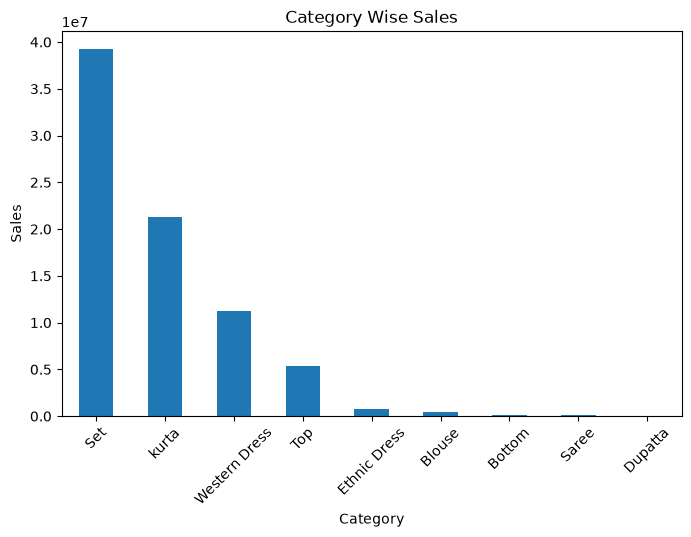

In [12]:
#analyse category wise sales
category_sales=df.groupby('Category')['Amount'].sum().sort_values(ascending=False)
category_sales.plot(kind='bar',figsize=(8,5))
plt.title("Category Wise Sales")
plt.xlabel("Category")
plt.ylabel("Sales")
plt.xticks(rotation=45)
plt.savefig("category_wise_sales.png",dpi=300,bbox_inches="tight")
plt.show()

top 10 states by sales

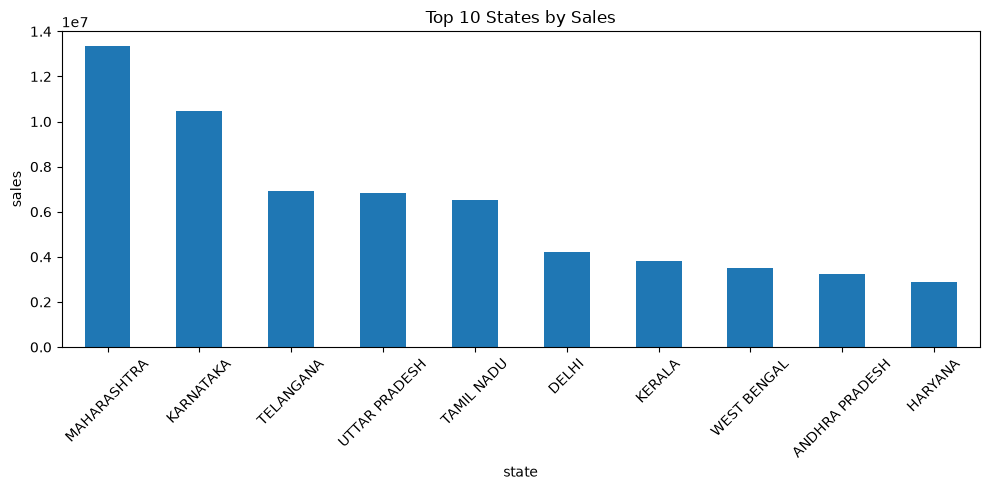

In [13]:

state_sales=df.groupby('ship-state')['Amount'].sum().sort_values(ascending=False).head(10)
plt.figure(figsize=(10,5))
state_sales.plot(kind='bar')
plt.title("Top 10 States by Sales")
plt.xlabel("state")
plt.ylabel("sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# monthly sales trend analysis

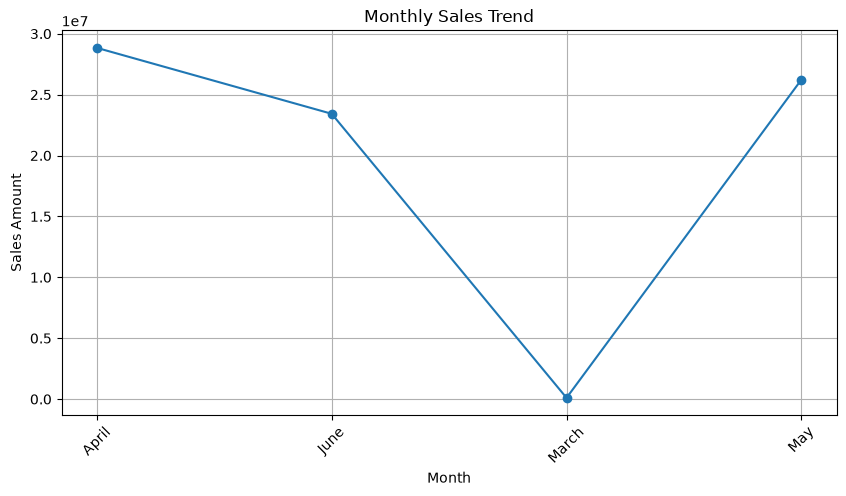

In [14]:
monthly_sales=df.groupby('Month')['Amount'].sum().sort_index()
plt.figure(figsize=(10,5))
plt.plot(monthly_sales.index,monthly_sales.values,marker='o')
plt.title('Monthly Sales Trend')
plt.xlabel('Month')
plt.ylabel('Sales Amount')
plt.xticks(rotation=45)
plt.grid(True)
plt.show()

# order status analysis

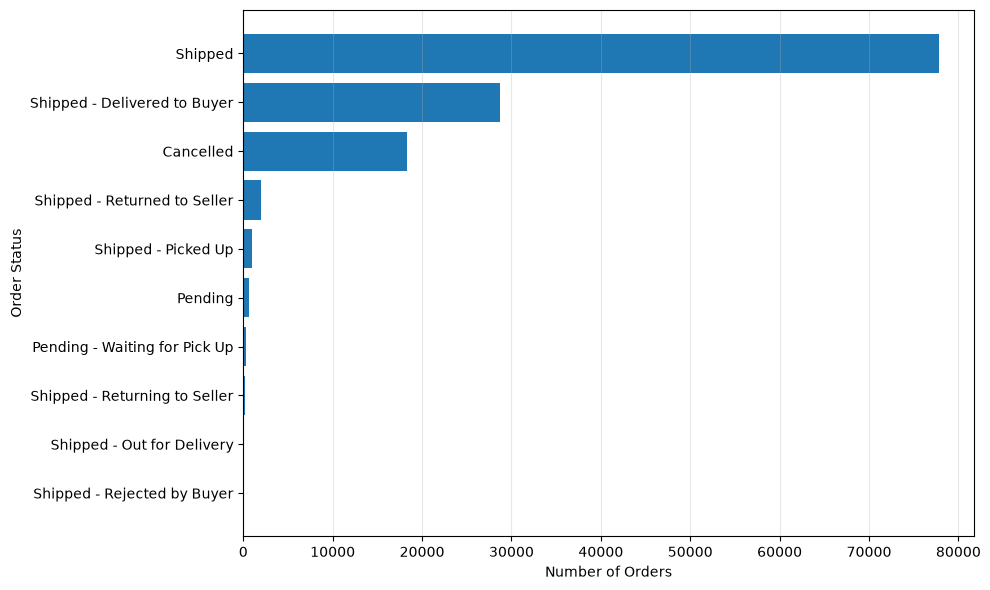

In [15]:
status_count=df['Status'].value_counts().head(10).sort_values()
plt.figure(figsize=(10,6))
plt.barh(status_count.index,status_count.values)

plt.xlabel('Number of Orders')
plt.ylabel('Order Status')
plt.grid(axis='x',alpha=0.3)
plt.tight_layout()
plt.show()

# fulfilment-wise sales analyis


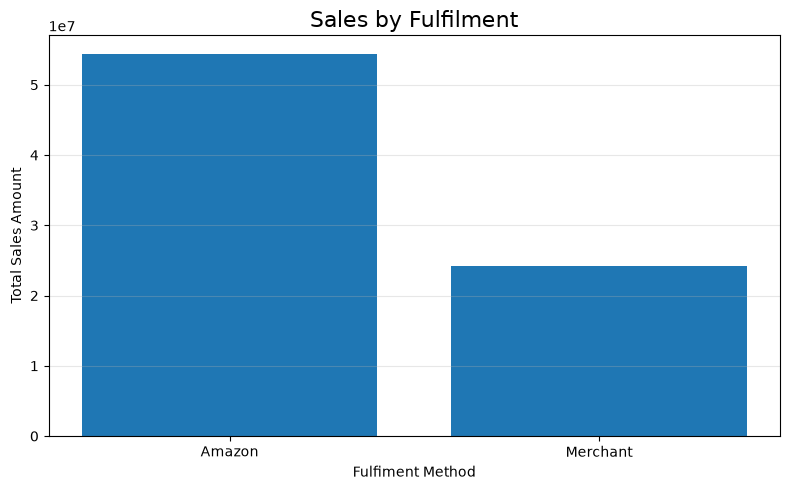

In [16]:
fulfilment_sales=df.groupby('Fulfilment')['Amount'].sum().sort_values(ascending=False)
plt.figure(figsize=(8,5))
plt.bar(fulfilment_sales.index,fulfilment_sales.values)
plt.title('Sales by Fulfilment',fontsize=16)
plt.xlabel('Fulfiment Method')
plt.ylabel('Total Sales Amount')
plt.grid(axis='y',alpha=0.3)
plt.tight_layout()
plt.show()

# top 10 products by sales

SKU
J0230-SKD-M        527699.20
JNE3797-KR-L       524581.77
J0230-SKD-S        479937.14
JNE3797-KR-M       454290.16
JNE3797-KR-S       407302.57
JNE3797-KR-XL      332155.24
J0230-SKD-L        305616.95
JNE3797-KR-XS      303616.70
SET268-KR-NP-XL    284058.96
JNE3797-KR-XXXL    276375.80
Name: Amount, dtype: float64


<Axes: title={'center': 'Top 10 Products by Sales'}, ylabel='SKU'>

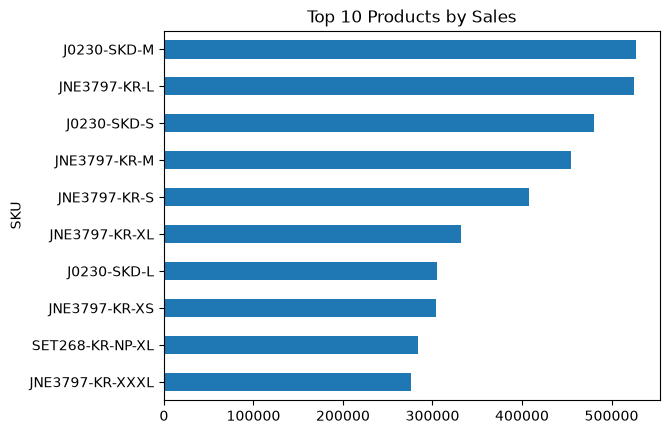

In [17]:
top10 = (df.groupby('SKU')['Amount'].sum()
           .sort_values(ascending=False).head(10))
print(top10)
top10.sort_values().plot(kind='barh', title='Top 10 Products by Sales')

category-wise monthly trend


<Axes: title={'center': 'Category-wise Monthly Sales'}, xlabel='Month'>

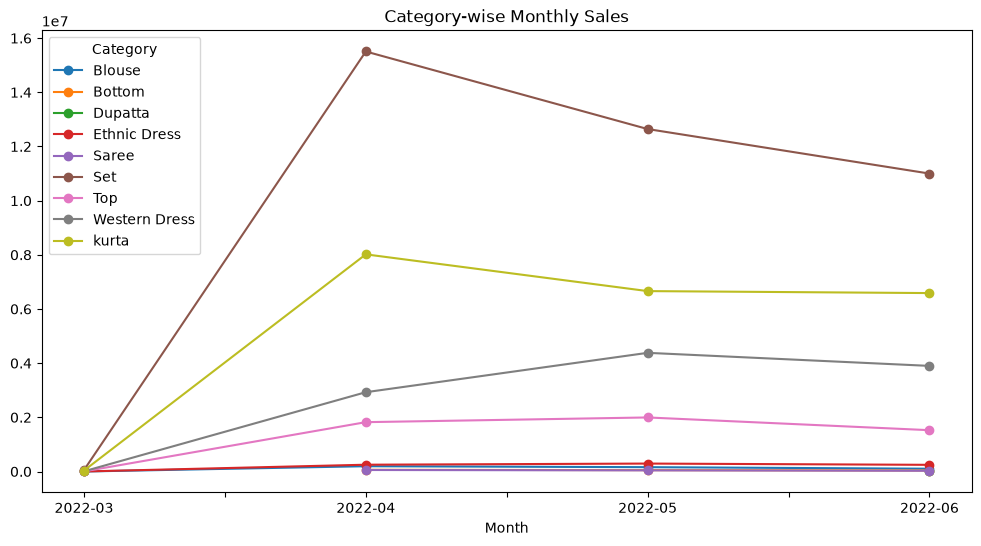

In [18]:
df['Date'] = pd.to_datetime(df['Date'])
df['Month'] = df['Date'].dt.to_period('M').astype(str)

cat_month = df.groupby(['Month', 'Category'])['Amount'].sum().unstack()
cat_month.plot(figsize=(12,6), marker='o', title='Category-wise Monthly Sales')

top 10 cities by sales

<Axes: title={'center': 'Top 10 Cities by Sales'}, ylabel='ship-city'>

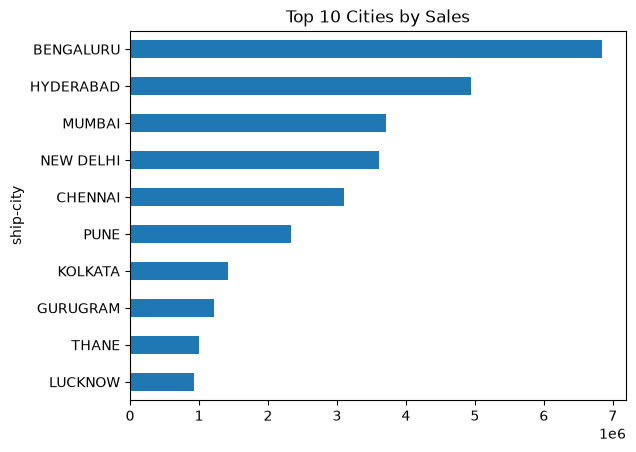

In [19]:
top_cities = df.groupby('ship-city')['Amount'].sum().nlargest(10)
top_cities.sort_values().plot(kind='barh', title='Top 10 Cities by Sales')

size analysis

<Axes: title={'center': 'Qty Sold by Size'}, xlabel='Size'>

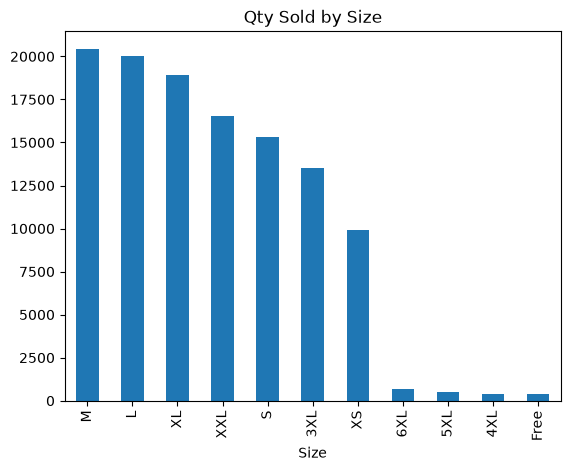

In [20]:
size_sales = df.groupby('Size')['Qty'].sum().sort_values(ascending=False)
size_sales.plot(kind='bar', title='Qty Sold by Size')

Cancellation rate Amazon vs Merchant

Fulfilment
Amazon      12.788468
Merchant    17.468238
Name: Cancelled, dtype: float64


<Axes: title={'center': 'Cancellation % by Fulfilment'}, xlabel='Fulfilment'>

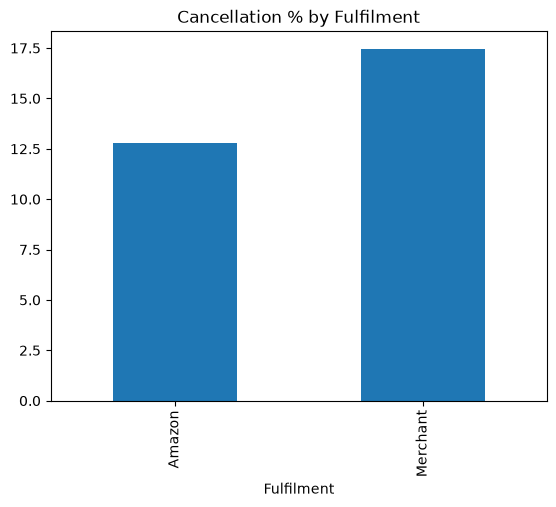

In [21]:
cancel = pd.crosstab(df['Fulfilment'], df['Status'], normalize='index') * 100
print(cancel['Cancelled'])
cancel['Cancelled'].plot(kind='bar', title='Cancellation % by Fulfilment')

Key Performance Indicators(KPI) Summary

In [22]:
total_sales = df['Amount'].sum()
total_orders = df['Order ID'].nunique()
total_qty = df['Qty'].sum()
aov = total_sales / total_orders

print("Total Sales:", round(total_sales))
print("Total Orders:", total_orders)
print("Total Qty:", total_qty)
print("Average Order Value:", round(aov))

Total Sales: 78592678
Total Orders: 120378
Total Qty: 116649
Average Order Value: 653


In [23]:
cat = df.groupby('Category')['Amount'].sum().sort_values(ascending=False)
print("Top category:", cat.index[0], round(cat.iloc[0] / cat.sum() * 100, 1), "%")

monthly = df.groupby('Month')['Amount'].sum()
print("Peak month:", monthly.idxmax())

print(df.groupby('ship-state')['Amount'].sum().nlargest(3))
print(df.groupby('SKU')['Amount'].sum().nlargest(1))
print(pd.crosstab(df['Fulfilment'], df['Status'], normalize='index')['Cancelled'] * 100)

Top category: Set 49.9 %
Peak month: 2022-04
ship-state
MAHARASHTRA    13335534.14
KARNATAKA      10481114.37
TELANGANA       6916615.65
Name: Amount, dtype: float64
SKU
J0230-SKD-M    527699.2
Name: Amount, dtype: float64
Fulfilment
Amazon      12.788468
Merchant    17.468238
Name: Cancelled, dtype: float64


 Key Insights

- The Set category is the top category, contributing 49.9% of total sales.
- Sales peaked in April 2022 and declined in the following months.
- The top 3 states by sales are Maharashtra (13.34 million), Karnataka (10.48 million) and Telangana (6.92 million).
- The top selling product is SKU J0230-SKD-M, with sales of about 527,699.
- The cancellation rate is 12.8% for Amazon fulfilment and 17.5% for Merchant fulfilment.

 Recommendations

- Keep more stock of the top selling products, especially in the Set category, since it drives about half of total sales.
- Reduce cancellations, mainly for Merchant fulfilment (17.5%), by improving stock availability and shipping speed.
- Focus marketing on the top states: Maharashtra, Karnataka and Telangana.
- Offer discounts and promotions in low sales months to lift sales after the April 2022 peak.